In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("zomato_cleaned.csv")

quality_df = df[df["rating_clean"].notna()].copy()

X = quality_df[["rating_clean", "log_votes"]]

In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

[6013.374033045872]
[6013.374033045872, 4257.16530060928]
[6013.374033045872, 4257.16530060928, 3298.177860770874]
[6013.374033045872, 4257.16530060928, 3298.177860770874, 2618.816401567999]
[6013.374033045872, 4257.16530060928, 3298.177860770874, 2618.816401567999, 2173.4223534765424]


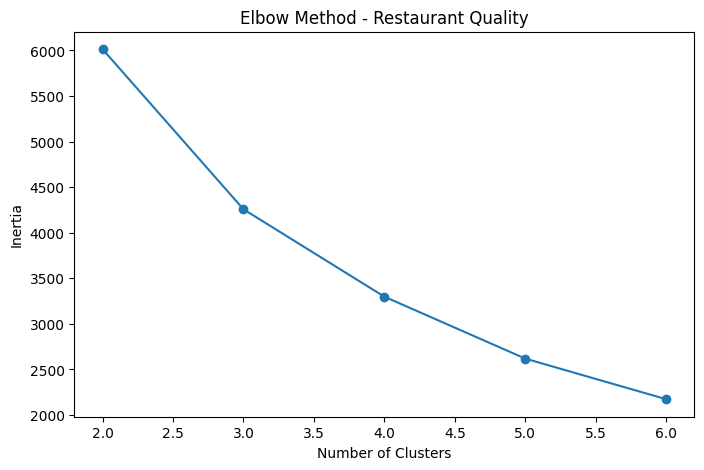

In [3]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    print(inertia)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method - Restaurant Quality")

plt.show()

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
s_score=[]
for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    s_score.append(score)

    print("Clusters:", k, "Silhouette Score:", round(score, 3))

Clusters: 2 Silhouette Score: 0.495
Clusters: 3 Silhouette Score: 0.396
Clusters: 4 Silhouette Score: 0.406
Clusters: 5 Silhouette Score: 0.385
Clusters: 6 Silhouette Score: 0.391


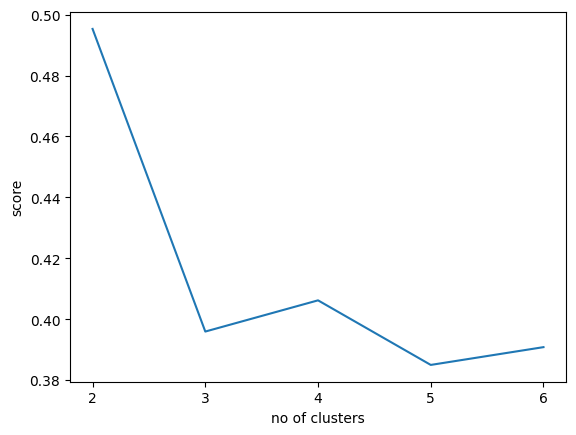

In [8]:
plt.plot(range(2,7),s_score)
plt.xticks(range(2,7))
plt.xlabel("no of clusters")
plt.ylabel("score")
plt.show()

In [9]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

quality_df["quality_cluster"] = kmeans.fit_predict(X_scaled)

In [10]:
quality_df.head()

,restaurant_id,restaurant_name,country_code,city,address,locality,locality_verbose,longitude,latitude,cuisines,...,rating_color,rating_text,votes,rating_status,rating_clean,log_votes,price_category,rating_category,primary_cuisine,quality_cluster
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Dark Green,Excellent,314,Rated,4.8,5.752573,Premium,Excellent,French,1
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Dark Green,Excellent,591,Rated,4.5,6.383507,Premium,Excellent,Japanese,1
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Green,Very Good,270,Rated,4.4,5.602119,Luxury,Very Good,Seafood,1
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Dark Green,Excellent,365,Rated,4.9,5.902633,Luxury,Excellent,Japanese,1
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Dark Green,Excellent,229,Rated,4.8,5.438079,Luxury,Excellent,Japanese,1


In [11]:
cluster_summary = quality_df.groupby("quality_cluster").agg(
    restaurant_count=("restaurant_id", "count"),
    avg_rating=("rating_clean", "mean"),
    avg_votes=("votes", "mean")
)

print(cluster_summary.round(2))

                 restaurant_count  avg_rating  avg_votes
quality_cluster                                         
0                             760        2.61      82.79
1                            1800        4.13     638.65
2                            2270        3.04      12.94
3                            2573        3.56      99.07


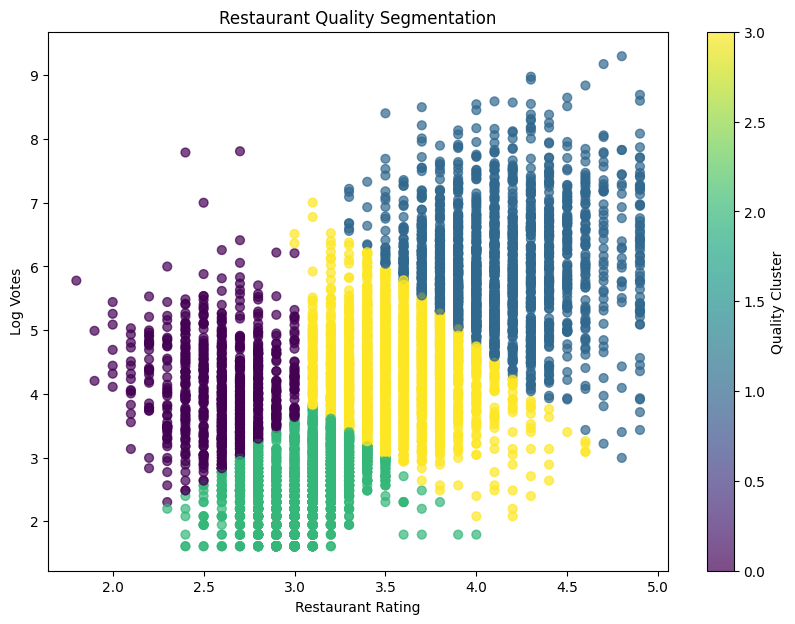

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    quality_df["rating_clean"],
    quality_df["log_votes"],
    c=quality_df["quality_cluster"],
    cmap="viridis",
    s=40,
    alpha=0.7
)

plt.xlabel("Restaurant Rating")
plt.ylabel("Log Votes")
plt.title("Restaurant Quality Segmentation")

plt.colorbar(label="Quality Cluster")

plt.show()

In [15]:
cluster_names = {
    0: "Low performence",
    1: "Average perfoemence",
    2: "Good performence",
    3: "High performence & Popular"
}

quality_df["performence_segment"] = (
    quality_df["quality_cluster"].map(cluster_names)
)

In [16]:
quality_df.head()

,restaurant_id,restaurant_name,country_code,city,address,locality,locality_verbose,longitude,latitude,cuisines,...,rating_text,votes,rating_status,rating_clean,log_votes,price_category,rating_category,primary_cuisine,quality_cluster,performence_segment
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Excellent,314,Rated,4.8,5.752573,Premium,Excellent,French,1,Average perfoemence
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Excellent,591,Rated,4.5,6.383507,Premium,Excellent,Japanese,1,Average perfoemence
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Very Good,270,Rated,4.4,5.602119,Luxury,Very Good,Seafood,1,Average perfoemence
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Excellent,365,Rated,4.9,5.902633,Luxury,Excellent,Japanese,1,Average perfoemence
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Excellent,229,Rated,4.8,5.438079,Luxury,Excellent,Japanese,1,Average perfoemence


In [17]:
quality_df.info()

<class 'pandas.DataFrame'>
Index: 7403 entries, 0 to 9550
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   restaurant_id         7403 non-null   int64  
 1   restaurant_name       7403 non-null   str    
 2   country_code          7403 non-null   int64  
 3   city                  7403 non-null   str    
 4   address               7403 non-null   str    
 5   locality              7403 non-null   str    
 6   locality_verbose      7403 non-null   str    
 7   longitude             7403 non-null   float64
 8   latitude              7403 non-null   float64
 9   cuisines              7403 non-null   str    
 10  average_cost_for_two  7403 non-null   int64  
 11  currency              7403 non-null   str    
 12  has_table_booking     7403 non-null   int64  
 13  has_online_delivery   7403 non-null   int64  
 14  is_delivering_now     7403 non-null   int64  
 15  price_range           7403 non-null  

In [18]:
quality_df.to_csv(
    "zomato_performence_segmented.csv",
    index=False
)